In [ ]:
from OptimizationModelforTesting import opmiziation_modeling_testing
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import os
from pathlib import Path
from tqdm.auto import tqdm

# make sure to save csv at output folder
if Path.cwd().name == "code":
    os.chdir(Path.cwd().parent)

capacity_base = [60, 80, 100, 120, 140, 160, 180, 200, 220, 250]

test_cases = [
    {"name": "slots_26",    "slots": 26, "capacity_rate": 1.00},
    {"name": "slots_25",    "slots": 25, "capacity_rate": 1.00},
  {"name": "slots_24(base)","slots": 24, "capacity_rate": 1.00},
    {"name": "slots_23",    "slots": 23, "capacity_rate": 1.00},
    {"name": "slots_22",    "slots": 22, "capacity_rate": 1.00},
    {"name": "capacity_80", "slots": 24, "capacity_rate": 0.80},
    {"name": "capacity_60", "slots": 24, "capacity_rate": 0.60},
    {"name": "capacity_40", "slots": 24, "capacity_rate": 0.40},
    {"name": "capacity_30", "slots": 24, "capacity_rate": 0.30},
    {"name": "capacity_25", "slots": 24, "capacity_rate": 0.25},
    {"name": "capacity_20", "slots": 24, "capacity_rate": 0.20},
]

status_names = {
    GRB.OPTIMAL: "OPTIMAL",
    GRB.INFEASIBLE: "INFEASIBLE",
    GRB.TIME_LIMIT: "TIME_LIMIT",
    GRB.INTERRUPTED: "INTERRUPTED",
}

test_results = []

for case in tqdm(test_cases, desc="Sensitivity Analysis", unit="test_case"):
    tqdm.write(f"\n===== {case['name']} =====")

    # rounding
    capacity = [ int(round(seats * case["capacity_rate"], 0)) for seats in capacity_base ]
    csv_name = f"{case['name']}_schedule.csv"

    print(f"\n===== {case['name']} =====")

    result = opmiziation_modeling_testing(
        slots=case["slots"],
        capacity=capacity,
        csv_name=csv_name,
    )

    # feasibility 
    if result["has_solution"]:
        feasibility = "Feasible"
    elif result["status"] == GRB.INFEASIBLE:
        feasibility = "Infeasible"
    else:
        feasibility = "Undecided"

    # save each result
    test_results.append({
        "test_name": case["name"],
        "slots": result["slots"],
        "capacity_percent": case["capacity_rate"] * 100,
        "status": status_names.get(result["status"], str(result["status"])),
        "feasibility": feasibility,
        "runtime_seconds": result["runtime"],
        "schedule_file": csv_name if result["has_solution"] else None,
        "objective": result["objective"],
        "best_bound": result["best_bound"],
        "mip_gap_percent": (result["mip_gap"] * 100 if result["mip_gap"] is not None else None),
        "exam_days": (result["slots"] + 5) // 6,
    })

# save the results to csv
test_results_df = pd.DataFrame(test_results)
test_results_df.to_csv("outputs/test_results.csv", index=False)

display(test_results_df)

c:\Users\user\anaconda3\envs\ise3230\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Sensitivity Analysis:   0%|          | 0/11 [00:00<?, ?test_case/s]


===== slots_26 =====

===== slots_26 =====
--- Data Simulation Complete ---
Courses: 25 | Rooms: 10 | Time Slots: 26 | Students: 400
Set parameter Username
Set parameter LicenseID to value 2858131
Academic license - for non-commercial use only - expires 2027-08-28
Set parameter LogToConsole to value 0
Optimizing model with Gurobi...


Sensitivity Analysis:   9%|▉         | 1/11 [05:01<50:17, 301.71s/test_case]


Solution found! Status: 9
Back-to-back objective: 46
Relative MIP gap: 100.00%
Exam schedule exported to 'outputs/slots_26_schedule.csv'!
   Course  Enrollment Assigned_Room  Room_Capacity Time_Slot  Day
0  CS_100          60      Room_102             80    Slot_4    1
1  CS_110          60      Room_107            180   Slot_13    3
2  CS_120          56      Room_105            140    Slot_7    2
3  CS_130          60      Room_105            140   Slot_19    4
4  CS_140          52      Room_105            140    Slot_9    2
5  CS_150          55      Room_110            250   Slot_24    4
6  CS_160          58      Room_110            250   Slot_23    4
7  CS_170          57      Room_109            220   Slot_26    5
8  CS_180          62      Room_110            250   Slot_25    5
9  CS_190          59      Room_101             60   Slot_15    3

===== slots_25 =====

===== slots_25 =====
--- Data Simulation Complete ---
Courses: 25 | Rooms: 10 | Time Slots: 25 | Students: 400
S

Sensitivity Analysis:  18%|█▊        | 2/11 [09:14<40:57, 273.02s/test_case]


Solution found! Status: 11
Back-to-back objective: 51
Relative MIP gap: 96.08%
Exam schedule exported to 'outputs/slots_25_schedule.csv'!
   Course  Enrollment Assigned_Room  Room_Capacity Time_Slot  Day
0  CS_100          60      Room_101             60   Slot_17    3
1  CS_110          60      Room_103            100    Slot_5    1
2  CS_120          56      Room_103            100   Slot_13    3
3  CS_130          60      Room_107            180    Slot_3    1
4  CS_140          52      Room_106            160   Slot_10    2
5  CS_150          55      Room_105            140    Slot_7    2
6  CS_160          58      Room_105            140    Slot_8    2
7  CS_170          57      Room_109            220    Slot_6    1
8  CS_180          62      Room_103            100   Slot_21    4
9  CS_190          59      Room_103            100   Slot_14    3

===== slots_24(base) =====

===== slots_24(base) =====
--- Data Simulation Complete ---
Courses: 25 | Rooms: 10 | Time Slots: 24 | Stu

In [ ]:
test_results_df = pd.read_csv("outputs/test_results.csv")

# separate results by parameter
slots_df = test_results_df[test_results_df["capacity_percent"] == 100]
capacity_df = test_results_df[test_results_df["slots"] == 24]

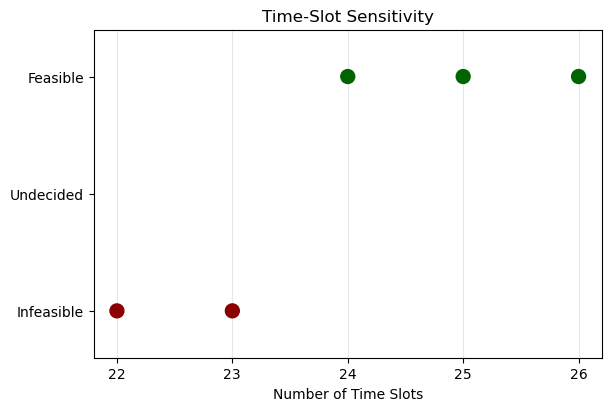

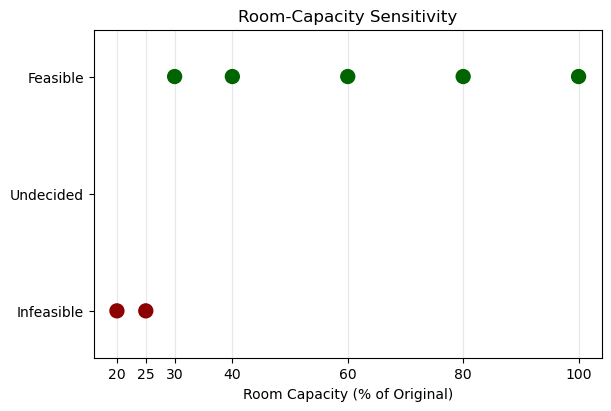

In [ ]:
import matplotlib.pyplot as plt

# separate the time-slot and room-capacity experiments.
slots_df = slots_df.sort_values("slots")

capacity_df = capacity_df.sort_values("capacity_percent")

# keep unresolved cases separate from infeasible cases.
feasibility_values = {
    "Infeasible": 0,
    "Undecided": 0.5,
    "Feasible": 1,
}

feasibility_colors = {
    "Infeasible": "darkred",
    "Undecided": "gray",
    "Feasible": "darkgreen",
}

for data, x_column, title, xlabel in [
    (
        slots_df,
        "slots",
        "Time-Slot Sensitivity",
        "Number of Time Slots",
    ),
    (
        capacity_df,
        "capacity_percent",
        "Room-Capacity Sensitivity",
        "Room Capacity (% of Original)",
    ),
]:
    
    fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")

    ax.scatter(
        data[x_column],
        data["feasibility"].map(feasibility_values),
        c=data["feasibility"].map(feasibility_colors),
        s=100,
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(data[x_column])
    ax.set_yticks(
        [0, 0.5, 1],
        ["Infeasible", "Undecided", "Feasible"],
    )
    ax.set_ylim(-0.2, 1.2)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.3)

    plt.show()

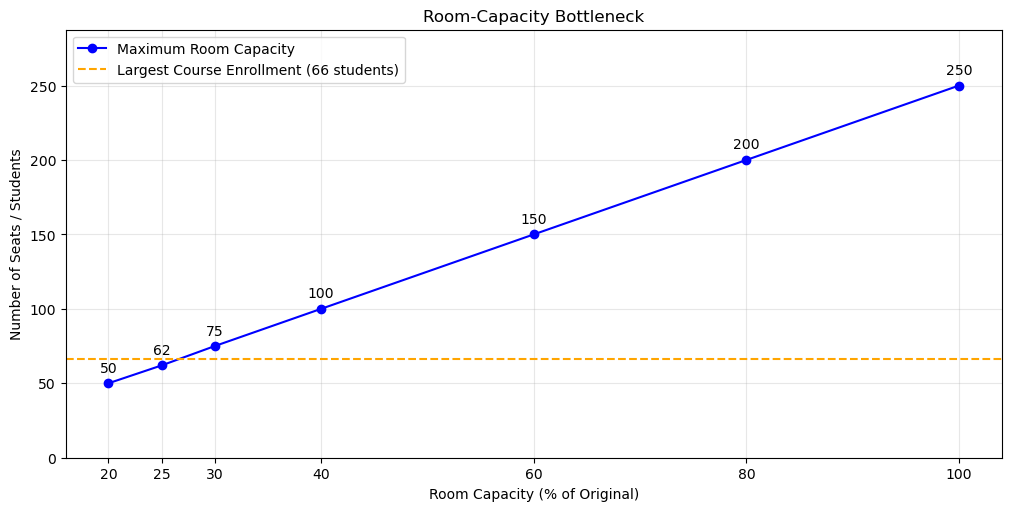

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# largest course enrollment in the baseline schedule.
student_df = pd.read_csv("data/student_enrollments.csv", index_col=0)
max_course = student_df.sum(axis=0).max()

# select capacity experiments while keeping 24 time slots fixed.
max_df = (test_results_df.loc[test_results_df["slots"] == 24, 
                                     ["capacity_percent", "feasibility"],].sort_values("capacity_percent").copy())

# the same capacity-rounding rule used in the test loop.
max_df["max_room_capacity"] = [int(round(max(capacity_base) * percent / 100)) 
                                      for percent in max_df["capacity_percent"]]

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

# the largest available room capacity for each case.
ax.plot(
    max_df["capacity_percent"],
    max_df["max_room_capacity"],
    marker="o",
    color="blue",
    label="Maximum Room Capacity",
)

# border line
ax.axhline(
    max_course,
    color="orange",
    linestyle="--",
    label=f"Largest Course Enrollment ({max_course} students)",
)

# label each tested room capacity.
for percent, seats in zip(
    max_df["capacity_percent"],
    max_df["max_room_capacity"],
):
    ax.annotate(
        str(seats),
        (percent, seats),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("Room-Capacity Bottleneck")
ax.set_xlabel("Room Capacity (% of Original)")
ax.set_ylabel("Number of Seats / Students")
ax.set_xticks(max_df["capacity_percent"])
ax.set_ylim(0, max_df["max_room_capacity"].max() * 1.15)
ax.grid(alpha=0.3)
ax.legend()

plt.show()